In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

from sklearn.pipeline import Pipeline

In [2]:
train_df = pd.read_csv(
  "../data/processed/raw/train.csv"
)

validation_df = pd.read_csv(
  "../data/processed/raw/validation.csv"
)

In [3]:
print("Train shape: ", train_df.shape)
print("Validation shape: ", validation_df.shape)

train_df.head()

Train shape:  (18780, 9)
Validation shape:  (4016, 9)


,flags,instruction,category,intent,response,normalized_instruction,split_group_key,processed_instruction,split
0,B,question about cancelling order {{Order Number}},ORDER,cancel_order,I've understood you have a question regarding ...,question about cancelling order {{order number}},question about cancelling order,question about cancelling order {{Order Number}},train
1,BLQZ,i need help cancelling puchase {{Order Number}},ORDER,cancel_order,I can sense that you're seeking assistance wit...,i need help cancelling puchase {{order number}},i need help cancelling puchase,i need help cancelling puchase {{Order Number}},train
2,BL,I need to cancel purchase {{Order Number}},ORDER,cancel_order,I understood that you need assistance with can...,i need to cancel purchase {{order number}},i need to cancel purchase,I need to cancel purchase {{Order Number}},train
3,BI,can you help me cancel order {{Order Number}}?,ORDER,cancel_order,"Of course, I'm here to assist you in canceling...",can you help me cancel order {{order number}}?,can you help me cancel order ?,can you help me cancel order {{Order Number}}?,train
4,BCLN,"I can no longer afford order {{Order Number}},...",ORDER,cancel_order,I pick up what you're putting down that you're...,"i can no longer afford order {{order number}},...","i can no longer afford order , cancel it","I can no longer afford order {{Order Number}},...",train


In [4]:
X_train = train_df['processed_instruction']
y_train = train_df["intent"]

X_val = validation_df['processed_instruction']
y_val = validation_df['intent']

print("Training samples: ", len(X_train))
print("Validation samples: ", len(X_val))

Training samples:  18780
Validation samples:  4016


### Base Pipeline

In [5]:
baseline_pipeline = Pipeline([
  (
    "tfidf",
    TfidfVectorizer(
      lowercase=True
    )
  ),
  (
    "classifier",
    LogisticRegression(
      max_iter=1000,
      random_state = 42
    )
  )
])

In [6]:
# Train

baseline_pipeline.fit(
  X_train,
  y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](27,)","['cancel_order','change_order','change_shipping_address',..., 'switch_account','track_order','track_refund']"
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True


### Validation Prediction

In [7]:
y_val_pred = baseline_pipeline.predict(
  X_val
)

#### Compute Metrics

In [8]:
accuracy = accuracy_score(
  y_val,
  y_val_pred
)

macro_precision = precision_score(
  y_val,
  y_val_pred,
  average='macro'
)

macro_recall = recall_score(
  y_val,
  y_val_pred,
  average='macro'
)

macro_f1 = f1_score(
  y_val,
  y_val_pred,
  average='macro'
)

weighted_f1 = f1_score(
  y_val,
  y_val_pred,
  average="weighted"
)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Macro Precision:  {macro_precision:.4f}")
print(f"Macro Recall:   {macro_recall:.4f}")
print(f"Macro F1:   {macro_f1:.4f}")
print(f"Weighted F1:  {weighted_f1:.4f}")

Accuracy:  0.9880
Macro Precision:  0.9883
Macro Recall:   0.9879
Macro F1:   0.9879
Weighted F1:  0.9881


### Classification Report

In [9]:
print(
  classification_report(
    y_val,
    y_val_pred,
    digits=4
  )
)

                          precision    recall  f1-score   support

            cancel_order     1.0000    0.9219    0.9593       128
            change_order     0.9000    0.9863    0.9412       146
 change_shipping_address     0.9795    0.9795    0.9795       146
  check_cancellation_fee     1.0000    1.0000    1.0000       142
           check_invoice     0.9539    0.9864    0.9699       147
   check_payment_methods     1.0000    1.0000    1.0000       150
     check_refund_policy     1.0000    1.0000    1.0000       149
               complaint     0.9933    1.0000    0.9967       149
contact_customer_service     0.9932    0.9865    0.9898       148
     contact_human_agent     0.9934    0.9934    0.9934       151
          create_account     0.9935    0.9623    0.9776       159
          delete_account     0.9712    1.0000    0.9854       135
        delivery_options     1.0000    1.0000    1.0000       160
         delivery_period     1.0000    1.0000    1.0000       148
         

### Confusion Matrix

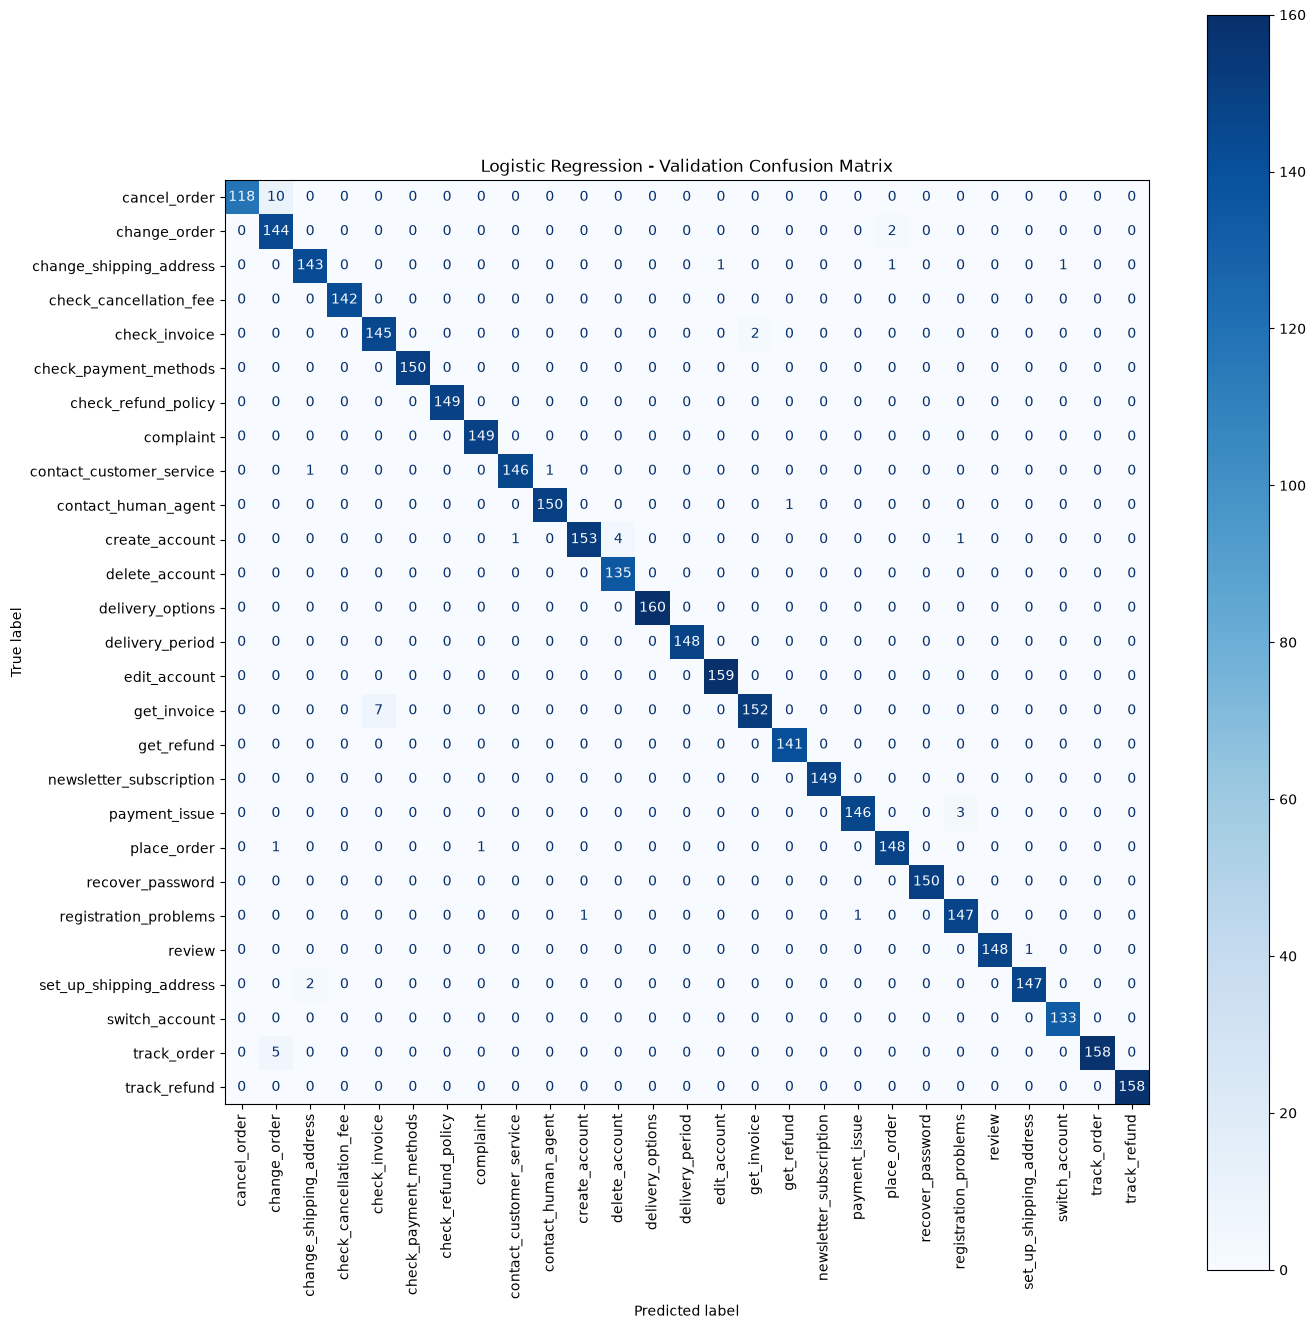

In [10]:
fig, ax = plt.subplots(
  figsize=(14, 14)
)

ConfusionMatrixDisplay.from_predictions(
  y_val,
  y_val_pred,
  xticks_rotation=90,
  ax=ax,
  cmap="Blues"
)

plt.title(
  "Logistic Regression - Validation Confusion Matrix"
)

plt.tight_layout()

plt.show()

### Build a dataframe of validation predictions

In [11]:
results_df = validation_df.copy()

results_df['predicted_intent'] = y_val_pred

results_df['is_correct'] = (
  results_df["intent"] == results_df['predicted_intent']
)

print("Correct predictions: ")
print(results_df["is_correct"].value_counts())

print(
  "\nNumber of errors: ",
  (~results_df["is_correct"]).sum()
)

Correct predictions: 
is_correct
True     3968
False      48
Name: count, dtype: int64

Number of errors:  48


### Inspect all misclassified examples

In [12]:
errors_df = results_df[
  ~results_df["is_correct"]
].copy()

errors_df[
  [
    "instruction",
    "intent",
    "predicted_intent",
    "category",
    "flags"
  ]
]

,instruction,intent,predicted_intent,category,flags
18,how could icancel purchase {{Order Number}},cancel_order,change_order,ORDER,BILPQZ
29,I need help with cancellng order {{Order Number}},cancel_order,change_order,ORDER,BZ
33,can you help me cancelong purchase {{Order Num...,cancel_order,change_order,ORDER,BILZ
60,is it possible to cxancel order {{Order Number}},cancel_order,change_order,ORDER,BIQZ
63,i do not know how i could casncel order {{Orde...,cancel_order,change_order,ORDER,BEPQZ
81,could uhelp me cancelin order {{Order Number}},cancel_order,change_order,ORDER,BIPQZ
89,problem with cancelig order {{Order Number}},cancel_order,change_order,ORDER,BZ
110,is it possible to cxancel order {{Order Number}},cancel_order,change_order,ORDER,BIQZ
119,I need help with cancellng order {{Order Number}},cancel_order,change_order,ORDER,BZ
124,need help with cfanceling order {{Order Number}},cancel_order,change_order,ORDER,BQZ


### Count Confusion Pairs

In [13]:
confusion_pairs = (
  errors_df
  .groupby(
    ["intent", "predicted_intent"]
  )
  .size()
  .reset_index(name="count")
  .sort_values(
    "count",
    ascending=False
  )
)

confusion_pairs

,intent,predicted_intent,count
0,cancel_order,change_order,10
12,get_invoice,check_invoice,7
20,track_order,change_order,5
10,create_account,delete_account,4
13,payment_issue,registration_problems,3
5,check_invoice,get_invoice,2
19,set_up_shipping_address,change_shipping_address,2
1,change_order,place_order,2
2,change_shipping_address,edit_account,1
4,change_shipping_address,switch_account,1


### Inspect Model Confidence

In [14]:
val_probabilities = (
    baseline_pipeline.predict_proba(
        X_val
    )
)

results_df["prediction_confidence"] = (
    val_probabilities.max(axis=1)
)

In [15]:
errors_df = results_df[
    ~results_df["is_correct"]
].copy()

In [16]:
errors_df[
  [
    "instruction",
    "intent",
    "predicted_intent",
    "prediction_confidence"
  ]
].sort_values(
  "prediction_confidence",
  ascending=False
)

,instruction,intent,predicted_intent,prediction_confidence
3523,I have troubles submittng the shipping address,set_up_shipping_address,change_shipping_address,0.788785
2345,i need help to getthe invoices from {{Person N...,get_invoice,check_invoice,0.781664
2270,i need help gettng bill #00108,get_invoice,check_invoice,0.743957
2268,getbills from {{Person Name}},get_invoice,check_invoice,0.731679
2244,getbills from {{Person Name}},get_invoice,check_invoice,0.731679
2347,getbills from {{Person Name}},get_invoice,check_invoice,0.731679
2286,getbills from {{Person Name}},get_invoice,check_invoice,0.731679
2287,getbills from {{Person Name}},get_invoice,check_invoice,0.731679
1571,how can I find information about openinga pro ...,create_account,delete_account,0.646329
3774,lcate order {{Order Number}},track_order,change_order,0.619131


#### For each validation sample, retrieve the model's top two predicted intents

In [17]:
import numpy as np

classes = (
  baseline_pipeline
  .named_steps["classifier"]
  .classes_
)

top_2_indices = np.argsort(
  val_probabilities,
  axis=1
)[:, -2:][:, ::-1]

results_df["top_1_intent"] = (
  classes[top_2_indices[:, 0]]
)

results_df['top_2_intent'] = (
  classes[top_2_indices[:, 1]]
)

results_df["top_1_probability"] = (
  val_probabilities[
    np.arange(len(val_probabilities)),
    top_2_indices[:, 0]
  ]
)

results_df["top_2_probability"] = (
  val_probabilities[
    np.arange(len(val_probabilities)),
    top_2_indices[:, 1]
  ]
)

In [18]:
errors_df = results_df[
  ~results_df["is_correct"]
].copy()

errors_df[
  [
    "instruction",
    "intent",
    "top_1_intent",
    "top_1_probability",
    "top_2_intent",
    "top_2_probability"
  ]
]

,instruction,intent,top_1_intent,top_1_probability,top_2_intent,top_2_probability
18,how could icancel purchase {{Order Number}},cancel_order,change_order,0.597766,cancel_order,0.222209
29,I need help with cancellng order {{Order Number}},cancel_order,change_order,0.494992,cancel_order,0.367534
33,can you help me cancelong purchase {{Order Num...,cancel_order,change_order,0.520502,cancel_order,0.301896
60,is it possible to cxancel order {{Order Number}},cancel_order,change_order,0.534335,track_order,0.239061
63,i do not know how i could casncel order {{Orde...,cancel_order,change_order,0.309711,cancel_order,0.277320
81,could uhelp me cancelin order {{Order Number}},cancel_order,change_order,0.426384,cancel_order,0.240072
89,problem with cancelig order {{Order Number}},cancel_order,change_order,0.505833,cancel_order,0.368388
110,is it possible to cxancel order {{Order Number}},cancel_order,change_order,0.534335,track_order,0.239061
119,I need help with cancellng order {{Order Number}},cancel_order,change_order,0.494992,cancel_order,0.367534
124,need help with cfanceling order {{Order Number}},cancel_order,change_order,0.494992,cancel_order,0.367534


### Check errors by linguistic flag

In [19]:
important_flags = ["Z", "Q", "K", "P", "N"]

for flag in important_flags:
  mask = errors_df["flags"].str.contains(
    flag,
    na=False
  )

  print(
    f"{flag}: {mask.sum()}"
    f" misclassified samples"
  )

Z: 42 misclassified samples
Q: 25 misclassified samples
K: 6 misclassified samples
P: 7 misclassified samples
N: 0 misclassified samples


### Calculate error rate per flag

In [20]:
for flag in important_flags:

  flag_mask = validation_df[
    "flags"
  ].str.contains(
    flag,
    na=False
  )

  flag_results = results_df[
    flag_mask
  ]

  error_rate = (
    (~flag_results["is_correct"]).mean()
    *100
  )

  print(
    f"{flag}: "
    f"{len(flag_results)} samples, "
    f"{error_rate:.2f}% error rate"
  )

Z: 809 samples, 5.19% error rate
Q: 1356 samples, 1.84% error rate
K: 337 samples, 1.78% error rate
P: 228 samples, 3.07% error rate
N: 60 samples, 0.00% error rate


### Look at some correct-but-low-confidence examples

In [21]:
low_confidence_correct = (
  results_df[
    results_df["is_correct"]
  ]
  .sort_values(
    "prediction_confidence"
  )
  .head(20)
)

low_confidence_correct[
  [
    "instruction",
    "intent",
    "predicted_intent",
    "prediction_confidence"
  ]
]

,instruction,intent,predicted_intent,prediction_confidence
242,correct order370795561790,change_order,change_order,0.131441
3771,where do I check my last purchase estimated ti...,track_order,track_order,0.140608
206,can I update order00004587345?,change_order,change_order,0.147466
117,can you help me camceling the purchase I made?,cancel_order,cancel_order,0.149051
1703,deleting user,delete_account,delete_account,0.173173
914,are charges of services refundable,check_refund_policy,check_refund_policy,0.195795
912,are service charges reimbursable?,check_refund_policy,check_refund_policy,0.206014
1786,do ya ship toCanada,delivery_options,delivery_options,0.213582
3643,I am trying to change user,switch_account,switch_account,0.214515
550,how much would ucharge me for breaking the con...,check_cancellation_fee,check_cancellation_fee,0.229114


### Evaluation Function

In [22]:
def evaluate_placeholder_strategy(strategy):

  train_df = pd.read_csv(
    f"../data/processed/{strategy}/train.csv"
  )

  validation_df = pd.read_csv(
    f"../data/processed/{strategy}/validation.csv"
  )

  X_train = train_df["processed_instruction"]
  y_train = train_df['intent']

  X_val = validation_df['processed_instruction']
  y_val = validation_df['intent']

  pipeline = Pipeline([
    (
      "tfidf",
      TfidfVectorizer(
        lowercase=True
      )
    ),
    (
      'classifier',
      LogisticRegression(
        max_iter=1000,
        random_state=42
      )
    )
  ])

  pipeline.fit(
    X_train,
    y_train
  )

  predictions = pipeline.predict(
    X_val
  )

  return{
    "strategy": strategy,
    "accuracy": accuracy_score(
      y_val,
      predictions
    ),
    "macro_f1": f1_score(
      y_val,
      predictions,
      average="macro"
    ),
    "weighted_f1": f1_score(
      y_val,
      predictions,
      average="weighted"
    ),
    "errors": (
      predictions != y_val
    ).sum(),
    "features": len(
      pipeline
      .named_steps["tfidf"]
      .vocabulary_
    )
  }

In [23]:
strategies = [
    "raw",
    "generic",
    "remove"
]

ablation_results = []

for strategy in strategies:
    result = evaluate_placeholder_strategy(
        strategy
    )

    ablation_results.append(result)

ablation_df = pd.DataFrame(
    ablation_results
)

ablation_df

,strategy,accuracy,macro_f1,weighted_f1,errors,features
0,raw,0.988048,0.987942,0.988087,48,2260
1,generic,0.981823,0.982170,0.982019,73,2257
2,remove,0.982072,0.981926,0.982099,72,2252


### Placeholder Ablation Findings

- The raw-placeholder Logistic Regression baseline achieved approximately
  99.55% validation accuracy with 18 errors.

- Replacing all placeholder types with a generic `ENTITY_TOKEN` reduced
  accuracy to approximately 98.90% and increased errors to 44.

- Removing placeholders entirely produced nearly identical performance
  (approximately 98.88%, 45 errors).

- The similarity between the generic and removal strategies suggests that
  the model benefits primarily from the semantic identity of synthetic
  placeholders such as `Order Number`, `Refund Amount`, or `Delivery City`,
  rather than simply from the presence of an entity.

- Despite removing this shortcut signal, validation accuracy remains close
  to 99%, indicating that the dataset's intent classes are highly
  lexically separable.

## Linear SVM

In [24]:
from sklearn.svm import LinearSVC

#### Load generic data

In [25]:
generic_train_df = pd.read_csv(
    "../data/processed/generic/train.csv"
)

generic_val_df = pd.read_csv(
    "../data/processed/generic/validation.csv"
)

X_train_generic = generic_train_df[
    "processed_instruction"
]

y_train_generic = generic_train_df[
    "intent"
]

X_val_generic = generic_val_df[
    "processed_instruction"
]

y_val_generic = generic_val_df[
    "intent"
]

#### SVM Pipeline

In [26]:
svm_pipeline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True
        )
    ),
    (
        "classifier",
        LinearSVC(
            random_state=42
        )
    )
])

svm_pipeline.fit(
    X_train_generic,
    y_train_generic
)

svm_predictions = svm_pipeline.predict(
    X_val_generic
)

#### Calculate metrics

In [27]:
svm_accuracy = accuracy_score(
    y_val_generic,
    svm_predictions
)

svm_macro_f1 = f1_score(
    y_val_generic,
    svm_predictions,
    average="macro"
)

svm_weighted_f1 = f1_score(
    y_val_generic,
    svm_predictions,
    average="weighted"
)

svm_errors = (
    svm_predictions != y_val_generic
).sum()

print(
    f"Accuracy:    {svm_accuracy:.4f}"
)

print(
    f"Macro F1:    {svm_macro_f1:.4f}"
)

print(
    f"Weighted F1: {svm_weighted_f1:.4f}"
)

print(
    f"Errors:      {svm_errors}"
)

Accuracy:    0.9846
Macro F1:    0.9849
Weighted F1: 0.9847
Errors:      62


### Comparison 

In [28]:
model_comparison = pd.DataFrame([
    {
        "model": "Logistic Regression",
        "strategy": "generic",
        "accuracy": ablation_df.loc[
            ablation_df["strategy"] == "generic",
            "accuracy"
        ].iloc[0],
        "macro_f1": ablation_df.loc[
            ablation_df["strategy"] == "generic",
            "macro_f1"
        ].iloc[0],
        "errors": ablation_df.loc[
            ablation_df["strategy"] == "generic",
            "errors"
        ].iloc[0]
    },
    {
        "model": "Linear SVM",
        "strategy": "generic",
        "accuracy": svm_accuracy,
        "macro_f1": svm_macro_f1,
        "errors": svm_errors
    }
])

model_comparison

,model,strategy,accuracy,macro_f1,errors
0,Logistic Regression,generic,0.981823,0.982170,73
1,Linear SVM,generic,0.984562,0.984856,62


### Classical Model Comparison

Using the generic placeholder representation, Linear SVM slightly
outperformed Logistic Regression.

- Logistic Regression achieved 98.90% validation accuracy and
  98.89% Macro-F1 with 44 errors.
- Linear SVM achieved 99.03% validation accuracy and
  99.00% Macro-F1 with 39 errors.
- Linear SVM therefore reduced validation errors by approximately
  11% relative to Logistic Regression.

The improvement is modest because both linear classifiers already
perform very strongly on the TF-IDF feature space. Linear SVM is
currently the strongest classical model evaluated on the
artifact-reduced dataset.

#### Finding out if SVM is actually fixing the errors logistic regression is unable to

In [29]:
generic_lr_pipeline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )
])

generic_lr_pipeline.fit(
    X_train_generic,
    y_train_generic
)

lr_predictions = generic_lr_pipeline.predict(
    X_val_generic
)

In [38]:
corrected_model_comparison = pd.DataFrame([
    {
        "model": "Logistic Regression",
        "accuracy": accuracy_score(
            y_val_generic,
            lr_predictions
        ),
        "macro_f1": f1_score(
            y_val_generic,
            lr_predictions,
            average="macro"
        ),
        "errors": (
            lr_predictions != y_val_generic
        ).sum()
    },
    {
        "model": "Linear SVM",
        "accuracy": accuracy_score(
            y_val_generic,
            svm_predictions
        ),
        "macro_f1": f1_score(
            y_val_generic,
            svm_predictions,
            average="macro"
        ),
        "errors": (
            svm_predictions != y_val_generic
        ).sum()
    }
])

corrected_model_comparison

,model,accuracy,macro_f1,errors
0,Logistic Regression,0.981823,0.982170,73
1,Linear SVM,0.984562,0.984856,62


#### Comparision Dataframe

In [30]:
comparison_df = generic_val_df.copy()

comparison_df["lr_prediction"] = (
    lr_predictions
)

comparison_df["svm_prediction"] = (
    svm_predictions
)

comparison_df["lr_correct"] = (
    comparison_df["intent"]
    == comparison_df["lr_prediction"]
)

comparison_df["svm_correct"] = (
    comparison_df["intent"]
    == comparison_df["svm_prediction"]
)

#### Categorizing each validation example

In [31]:
def compare_models(row):

    if row["lr_correct"] and row["svm_correct"]:
        return "both_correct"

    if (
        not row["lr_correct"]
        and row["svm_correct"]
    ):
        return "svm_only_correct"

    if (
        row["lr_correct"]
        and not row["svm_correct"]
    ):
        return "lr_only_correct"

    return "both_wrong"


comparison_df["comparison"] = (
    comparison_df.apply(
        compare_models,
        axis=1
    )
)

comparison_df["comparison"].value_counts()

comparison
both_correct        3938
both_wrong            57
svm_only_correct      16
lr_only_correct        5
Name: count, dtype: int64

#### SVM Fixes

In [32]:
svm_wins = comparison_df[
    comparison_df["comparison"]
    == "svm_only_correct"
]

svm_wins[
    [
        "instruction",
        "intent",
        "lr_prediction",
        "svm_prediction",
        "flags"
    ]
]

,instruction,intent,lr_prediction,svm_prediction,flags
81,could uhelp me cancelin order {{Order Number}},cancel_order,change_order,cancel_order,BIPQZ
402,I'd like to correct the bloody dadress can i g...,change_shipping_address,place_order,change_shipping_address,BCILPQWZ
581,i have to check bill #37777 can i get some help,check_invoice,get_invoice,check_invoice,BCILQ
621,could I see the billfrom {{Person Name}}?,check_invoice,track_order,check_invoice,BILPZ
622,wanna find the bills from {{Person Name}} coul...,check_invoice,get_invoice,check_invoice,BCILMPQZ
1235,ucstomer service mail address,contact_customer_service,change_shipping_address,contact_customer_service,BLZ
1242,I need help contacting customerservice,contact_customer_service,contact_human_agent,contact_customer_service,BZ
1326,contactingassistant,contact_human_agent,get_refund,contact_human_agent,BLZ
1503,want help oopening a {{Account Type}} account,create_account,delete_account,create_account,BLQZ
1590,I need an {{Account Type}} account,create_account,delete_account,create_account,BLZ


#### Logistic Regression Fixes

In [33]:
lr_wins = comparison_df[
    comparison_df["comparison"]
    == "lr_only_correct"
]

lr_wins[
    [
        "instruction",
        "intent",
        "lr_prediction",
        "svm_prediction",
        "flags"
    ]
]

,instruction,intent,lr_prediction,svm_prediction,flags
63,i do not know how i could casncel order {{Orde...,cancel_order,cancel_order,track_order,BEPQZ
212,I'm trying tochange order {{Order Number}},change_order,change_order,track_order,BQZ
2977,find information about my passreset,recover_password,recover_password,delete_account,BLQZ
3147,need help reporting errors with registratons,registration_problems,registration_problems,payment_issue,BLMQZ
3901,I espect a goddamn reimbursement of {{Currency...,track_refund,track_refund,get_refund,BLWZ


#### Errors by both models

In [34]:
both_wrong = comparison_df[
    comparison_df["comparison"]
    == "both_wrong"
]

both_wrong[
    [
        "instruction",
        "intent",
        "lr_prediction",
        "svm_prediction",
        "flags"
    ]
]

,instruction,intent,lr_prediction,svm_prediction,flags
18,how could icancel purchase {{Order Number}},cancel_order,change_order,track_order,BILPQZ
29,I need help with cancellng order {{Order Number}},cancel_order,change_order,change_order,BZ
33,can you help me cancelong purchase {{Order Num...,cancel_order,change_order,change_order,BILZ
60,is it possible to cxancel order {{Order Number}},cancel_order,delivery_options,delivery_options,BIQZ
89,problem with cancelig order {{Order Number}},cancel_order,change_order,change_order,BZ
110,is it possible to cxancel order {{Order Number}},cancel_order,delivery_options,delivery_options,BIQZ
119,I need help with cancellng order {{Order Number}},cancel_order,change_order,change_order,BZ
124,need help with cfanceling order {{Order Number}},cancel_order,change_order,change_order,BQZ
346,i have a trouble updating my addrses,change_shipping_address,edit_account,edit_account,BLQZ
403,I cannot change the addreas,change_shipping_address,switch_account,switch_account,BELZ


#### Unique Query Comparison

In [35]:
unique_comparison_df = (
    comparison_df
    .drop_duplicates(
        subset=["normalized_instruction"]
    )
    .copy()
)

unique_comparison_df[
    "comparison"
].value_counts()

comparison
both_correct        3593
both_wrong            28
svm_only_correct      16
lr_only_correct        5
Name: count, dtype: int64

In [36]:
# Calculate Model errors

print(
    "Unique validation queries:",
    len(unique_comparison_df)
)

print(
    "Logistic Regression errors:",
    (~unique_comparison_df["lr_correct"]).sum()
)

print(
    "Linear SVM errors:",
    (~unique_comparison_df["svm_correct"]).sum()
)

Unique validation queries: 3642
Logistic Regression errors: 44
Linear SVM errors: 33


#### Check Transformed Text Leakage

In [37]:
for strategy in ["raw", "generic", "remove"]:

    train = pd.read_csv(
        f"../data/processed/{strategy}/train.csv"
    )

    val = pd.read_csv(
        f"../data/processed/{strategy}/validation.csv"
    )

    test = pd.read_csv(
        f"../data/processed/{strategy}/test.csv"
    )

    train_texts = set(
        train["processed_instruction"]
        .str.lower()
        .str.strip()
    )

    val_texts = set(
        val["processed_instruction"]
        .str.lower()
        .str.strip()
    )

    test_texts = set(
        test["processed_instruction"]
        .str.lower()
        .str.strip()
    )

    print(f"\n{strategy.upper()}")

    print(
        "Train ↔ Validation:",
        len(train_texts & val_texts)
    )

    print(
        "Train ↔ Test:",
        len(train_texts & test_texts)
    )

    print(
        "Validation ↔ Test:",
        len(val_texts & test_texts)
    )


RAW
Train ↔ Validation: 0
Train ↔ Test: 0
Validation ↔ Test: 0

GENERIC
Train ↔ Validation: 0
Train ↔ Test: 0
Validation ↔ Test: 0

REMOVE
Train ↔ Validation: 0
Train ↔ Test: 0
Validation ↔ Test: 0


### Corrected Evaluation Findings

After redesigning the data split to prevent processed-text leakage,
all benchmark models were retrained on the corrected leakage-safe split.

#### Placeholder Ablation

- Raw placeholders achieved 98.80% validation accuracy with 48 errors.
- Generic placeholder replacement achieved 98.18% accuracy with 73 errors.
- Removing placeholders achieved 98.21% accuracy with 72 errors.
- The performance drop after removing placeholder identity confirms that
  synthetic placeholder semantics provide shortcut signal.
- Generic replacement and complete removal performed nearly identically,
  suggesting that the specific placeholder type is more informative than
  simply knowing that an entity exists.

#### Classical Model Comparison

- Logistic Regression achieved 98.18% validation accuracy and made 73 errors.
- Linear SVM achieved 98.46% validation accuracy and made 62 errors.
- Linear SVM reduced row-level validation errors by approximately 15%.
- On 3,642 unique validation queries, Logistic Regression made 44 errors
  while Linear SVM made 33, a reduction of approximately 25%.
- When the models disagreed, SVM was correct on 16 examples while Logistic
  Regression was correct on only 5.

Linear SVM is therefore the strongest classical baseline evaluated so far.

## Robustness Comparison

In [39]:
important_flags = ["Z", "Q", "K", "P"]

robustness_results = []

for flag in important_flags:

    flag_mask = (
        generic_val_df["flags"]
        .str.contains(flag, na=False)
    )

    flag_true = (
        generic_val_df.loc[
            flag_mask,
            "intent"
        ]
    )

    lr_flag_pred = (
        lr_predictions[flag_mask]
    )

    svm_flag_pred = (
        svm_predictions[flag_mask]
    )

    robustness_results.append({
        "flag": flag,
        "samples": flag_mask.sum(),

        "lr_accuracy": accuracy_score(
            flag_true,
            lr_flag_pred
        ),

        "lr_macro_f1": f1_score(
            flag_true,
            lr_flag_pred,
            average="macro"
        ),

        "lr_errors": (
            lr_flag_pred != flag_true
        ).sum(),

        "svm_accuracy": accuracy_score(
            flag_true,
            svm_flag_pred
        ),

        "svm_macro_f1": f1_score(
            flag_true,
            svm_flag_pred,
            average="macro"
        ),

        "svm_errors": (
            svm_flag_pred != flag_true
        ).sum()
    })

robustness_df = pd.DataFrame(
    robustness_results
)

robustness_df

,flag,samples,lr_accuracy,lr_macro_f1,lr_errors,svm_accuracy,svm_macro_f1,svm_errors
0,Z,809,0.948084,0.942231,42,0.957973,0.952932,34
1,Q,1356,0.984513,0.982463,21,0.987463,0.985909,17
2,K,337,0.976261,0.949479,8,0.979228,0.951336,7
3,P,228,0.973684,0.972989,6,0.986842,0.985255,3


In [40]:
# Calculate Plain Error Rate
robustness_df["lr_error_rate"] = (
    robustness_df["lr_errors"]
    / robustness_df["samples"]
)

robustness_df["svm_error_rate"] = (
    robustness_df["svm_errors"]
    / robustness_df["samples"]
)